# 2. Pré-processamento
Corrige os problemas encontrados na exploração e salva as bases limpas em `dados/`.

In [1]:
import os
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score


def primeira_letra(coluna):
    """Tira espaços, passa para maiúsculas e fica só com a primeira letra (ex.: ' female' vira 'F')."""
    return coluna.str.strip().str.upper().str[0]


def limpar(df):
    """Recebe a tabela original e devolve uma tabela limpa, com números nas unidades certas."""
    limpo = pd.DataFrame()
    limpo['id'] = df['id']
    limpo['patient'] = df['PATIENT_CODE']

    # Local de coleta: 'SITE-012' vira 12
    limpo['site'] = df['COLLECTION_SITE'].str.extract(r'(\d+)')[0].astype(int)

    # Sexo: várias grafias viram 1 (masculino) ou 0 (feminino)
    limpo['male'] = primeira_letra(df['GENDER']).map({'M': 1, 'F': 0})

    # Idade: valores impossíveis (0, -1, 999) são recalculados pelo ano de nascimento
    ano_exame = pd.to_datetime(df['EXAM_DATE'], format='mixed', dayfirst=True).dt.year
    idade_valida = df['AGE'].between(1, 110)
    limpo['age'] = np.where(idade_valida, df['AGE'], ano_exame - df['BIRTH_YEAR'])

    # Altura: valores em metros (até 3) viram centímetros
    altura = pd.to_numeric(df['HEIGHT'].str.replace(',', '.'))
    altura = np.where(altura <= 3, altura * 100, altura)

    # Peso: valores a partir de 130 estão em libras e viram quilos
    peso = np.where(df['WEIGHT'] >= 130, df['WEIGHT'] / 2.2046, df['WEIGHT'])
    limpo['bmi'] = peso / (altura / 100) ** 2

    # Pressão: '120/80', '120 / 80' ou '120x80' viram sistólica e diastólica ('?' vira ausente)
    pressao = df['BLOOD_PRESSURE'].str.extract(r'(\d+)\s*[/x]\s*(\d+)').astype(float)
    limpo['sbp'] = pressao[0]
    limpo['dbp'] = pressao[1]

    # Fumante, histórico familiar e atividade física: texto vira código numérico
    fumante = df['SMOKER'].str.strip().str.lower()
    limpo['smoker'] = fumante.map({'never': 0, 'former': 1, 'ex-smoker': 1, 'current': 2, 'yes': 2})
    limpo['fam_hist'] = primeira_letra(df['FAMILY_HISTORY']).map({'Y': 1, 'S': 1, '1': 1, 'N': 0, '0': 0})
    atividade = df['PHYSICAL_ACTIVITY'].str.strip().str.lower().str[:3]
    limpo['activity'] = atividade.map({'sed': 0, 'lig': 1, 'mod': 2, 'int': 3})

    # Glicose: valores até 30 estão em mmol/L e viram mg/dL
    limpo['glucose'] = np.where(df['GLUCOSE'] <= 30, df['GLUCOSE'] * 18.016, df['GLUCOSE'])

    # HbA1c: valores a partir de 20 estão em mmol/mol e viram %
    limpo['hba1c'] = np.where(df['HEMOGLOBIN'] >= 20, df['HEMOGLOBIN'] / 10.929 + 2.15, df['HEMOGLOBIN'])

    # Triglicerídeos: logaritmo, para diminuir o efeito de valores extremos
    limpo['trig'] = np.log(df['TRIGLYCERIDES'])
    limpo['sodium'] = df['SODIUM']

    # A coluna da resposta só existe no treino
    if 'class' in df.columns:
        limpo['class'] = df['class']
    return limpo

In [2]:
os.makedirs('dados', exist_ok=True)
treino = limpar(pd.read_csv('kaggle-training set/kaggle-training set/train.csv'))
teste = limpar(pd.read_csv('kaggle-test/kaggle-test/test.csv'))

# Salva as tabelas limpas para o notebook 3
treino.to_csv('dados/treino_limpo.csv', index=False)
teste.to_csv('dados/teste_limpo.csv', index=False)
treino.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
id,540.0,537.0,304.8,4.0,266.8,538.5,801.2,1058.0
site,540.0,10.0,13.6,1.0,1.0,4.0,13.0,60.0
male,534.0,0.4,0.5,0.0,0.0,0.0,1.0,1.0
age,540.0,56.9,13.4,16.0,49.0,57.0,67.0,98.0
bmi,495.0,28.0,5.0,16.5,24.8,27.9,31.1,46.5
sbp,498.0,123.4,15.5,90.0,113.0,124.0,134.0,175.0
dbp,498.0,81.6,8.3,53.0,76.0,81.0,87.8,107.0
smoker,363.0,0.6,0.8,0.0,0.0,0.0,1.0,2.0
fam_hist,488.0,0.3,0.5,0.0,0.0,0.0,1.0,1.0
activity,514.0,1.1,1.0,0.0,0.0,1.0,2.0,3.0


## 2.1 Quais variáveis separam as classes?
AUC de cada variável sozinha: 0,5 = não separa nada; 1,0 = separa perfeitamente.

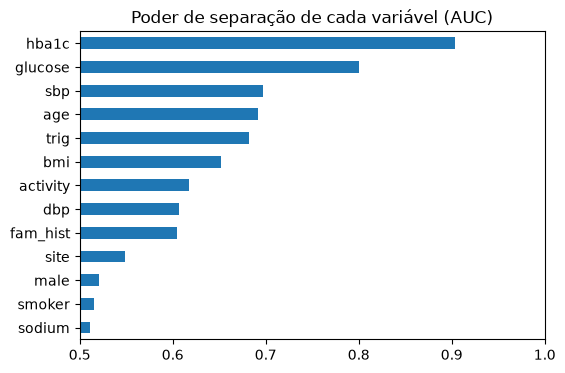

In [3]:
# AUC de cada variável sozinha (valores ausentes preenchidos com a mediana)
variaveis = treino.drop(columns=['id', 'patient', 'class'])
auc = {}
for coluna in variaveis.columns:
    valores = variaveis[coluna].fillna(variaveis[coluna].median())
    valor_auc = roc_auc_score(treino['class'], valores)
    # uma AUC de 0,3 separa tão bem quanto 0,7, só que no sentido contrário
    auc[coluna] = max(valor_auc, 1 - valor_auc)

auc = pd.Series(auc).sort_values()
auc.plot.barh(title='Poder de separação de cada variável (AUC)', xlim=(0.5, 1), figsize=(6, 4));

## 2.2 Descoberta principal: o critério clínico
O critério diagnóstico de diabetes da ADA é **HbA1c ≥ 6,5%**. No treino, **nenhum** paciente controle tem HbA1c ≥ 6,5% ou glicose > 140 mg/dL.

class,0,1
"HbA1c ≥ 6,5 ou glicose > 140",,
False,259,67
True,0,214


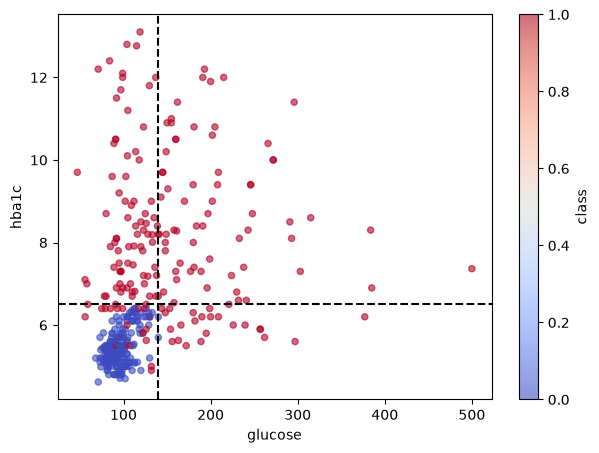

In [4]:
grafico = treino.plot.scatter('glucose', 'hba1c', c='class', cmap='coolwarm', alpha=0.6, figsize=(7, 5))
grafico.axhline(6.5, linestyle='--', color='black')   # HbA1c = 6,5%
grafico.axvline(140, linestyle='--', color='black')   # glicose = 140 mg/dL

regra = (treino['hba1c'] >= 6.5) | (treino['glucose'] > 140)
pd.crosstab(regra, treino['class'], rownames=['HbA1c ≥ 6,5 ou glicose > 140'])

## 2.3 As variáveis são independentes dentro de cada classe?
Correlação entre as variáveis numéricas **separadamente** para controles e diabéticos.

In [5]:
colunas = ['age', 'sbp', 'dbp', 'bmi', 'trig', 'glucose', 'hba1c']

print('Correlação entre os controles')
display(treino[treino['class'] == 0][colunas].corr().round(2))

print('Correlação entre os diabéticos')
display(treino[treino['class'] == 1][colunas].corr().round(2))

Correlação entre os controles


,age,sbp,dbp,bmi,trig,glucose,hba1c
age,1.00,0.48,0.30,0.10,-0.11,0.13,0.18
sbp,0.48,1.00,0.58,0.02,-0.03,0.02,-0.03
dbp,0.30,0.58,1.00,0.08,0.07,-0.07,-0.07
bmi,0.10,0.02,0.08,1.00,0.05,-0.04,-0.10
trig,-0.11,-0.03,0.07,0.05,1.00,-0.13,-0.12
glucose,0.13,0.02,-0.07,-0.04,-0.13,1.00,0.50
hba1c,0.18,-0.03,-0.07,-0.10,-0.12,0.50,1.00


Correlação entre os diabéticos


,age,sbp,dbp,bmi,trig,glucose,hba1c
age,1.00,0.33,0.23,0.14,0.01,-0.14,0.04
sbp,0.33,1.00,0.60,0.01,-0.05,0.08,0.00
dbp,0.23,0.60,1.00,0.00,0.06,0.07,0.01
bmi,0.14,0.01,0.00,1.00,-0.03,-0.11,0.11
trig,0.01,-0.05,0.06,-0.03,1.00,0.01,0.04
glucose,-0.14,0.08,0.07,-0.11,0.01,1.00,-0.01
hba1c,0.04,0.00,0.01,0.11,0.04,-0.01,1.00


## Conclusões
- A **regra clínica acerta 100%** dos pacientes que ela cobre (~40% da base).
- O desafio são os ~60% restantes (HbA1c normal ou ausente): ali o modelo precisa combinar idade, triglicerídeos, pressão, IMC, histórico familiar etc.
- **Dentro de cada classe**, glicose e HbA1c quase não se correlacionam com as outras variáveis (|r| ≤ 0,18), enquanto idade e pressão andam juntas (0,2–0,6). Isso permite **separar a evidência glicêmica da não glicêmica** — a base do modelo final.
- Sexo, fumante e sódio têm AUC ≈ 0,5 (provavelmente atributos artificiais) → ficam de fora do modelo.